# Grupa B – niezbalansowane klasy i data leakage

Kontekst:

> Predykcję chcemy wykonywać **przed rozpoczęciem rozmowy z klientem**.

Przeczytaj również `readme/README_GRUPA_B.md`.

In [ ]:
!git clone https://github.com/poochacz/Podstawy_technologii_ML.git /content/eda_bank_marketing_colab

In [1]:
# Jednorazowe uruchomienie w Colabie:
# Jeśli pakiet został już rozpakowany w /content/eda_bank_marketing_colab,
# ta komórka tylko ustawi ścieżkę importów.
import sys
from pathlib import Path

COLAB_ROOT = Path("/content/eda_bank_marketing_colab/01_eda_bank_marketing_colab")
current = Path.cwd().resolve()
candidates = [COLAB_ROOT]
for directory in (current, *current.parents):
    candidates.extend((directory / "01_eda_bank_marketing_colab", directory))

ROOT = next(
    (candidate.resolve() for candidate in candidates if (candidate / "scripts").is_dir()),
    None,
)
if ROOT is None:
    raise FileNotFoundError(
        "Nie znaleziono katalogu projektu. Otwórz workspace zawierający "
        "01_eda_bank_marketing_colab albo uruchom notebook w Colabie."
    )

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

DATA_DIR = ROOT / "data"
print("Środowisko gotowe:", ROOT)

Środowisko gotowe: C:\Users\dariu\Documents\Studia Kato\Koźmiński\podstawy ML\podstawy_ML_repo\Podstawy_technologii_ML\01_eda_bank_marketing_colab


In [3]:
from scripts.data_setup import prepare_workshop_data

df, reference = prepare_workshop_data(
    data_dir=DATA_DIR,
    n=2000,
    random_state=42
)

## 1. Czy klasy są zbalansowane?

,liczba,udział
y,,
no,1779,0.8895
yes,221,0.1105


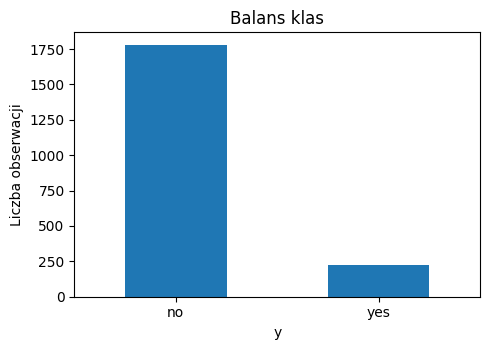

,liczba,udział
y,,
no,1779,0.8895
yes,221,0.1105


In [3]:
from scripts.group_b import target_balance

target_balance(df)

## 2. Jaki wynik daje banalny baseline?

In [4]:
from scripts.group_b import naive_baseline

naive_baseline(df)

Najczęstsza klasa: no
Accuracy modelu, który zawsze przewiduje 'no': 88.9%


{'zawsze_przewiduj': 'no', 'accuracy': 0.8895}

**Pytanie:** jeżeli model osiągnie podobną accuracy, czy rzeczywiście wnosi wartość?

## 3. Które cechy różnią klasy `yes` i `no`?

Tabela pokazuje wszystkie cechy poza wynikiem `y`. Dla cech liczbowych porównuje średnie, a dla kategorycznych wskazuje kategorię o największej różnicy udziałów między klientami, którzy założyli lokatę (`yes`), i tymi, którzy jej nie założyli (`no`). To opis porównawczy, nie dowód przyczynowości.

In [3]:
from scripts.group_b import feature_differences_by_target

porownanie_cech = feature_differences_by_target(df)
porownanie_cech

,cecha,typ,porównanie,wynik dla no,wynik dla yes,różnica (yes - no),liczba no / yes
0,age,liczbowa,średnia wartość,39.42,41.54,2.12,1762 / 220
1,job,kategoryczna,udział kategorii 'admin.' (%),22.80,35.30,12.50,1779 / 221
2,education,kategoryczna,udział kategorii 'university.degree' (%),25.40,36.20,10.80,1779 / 221
3,housing,kategoryczna,udział kategorii 'unknown' (%),2.80,0.90,-1.90,1779 / 221
4,contact,kategoryczna,udział kategorii 'telephone' (%),37.30,14.90,-22.30,1779 / 221
5,month,kategoryczna,udział kategorii 'may' (%),51.20,31.70,-19.50,1779 / 221
6,duration,liczbowa,średnia wartość,220.50,584.11,363.61,1768 / 220
7,campaign,liczbowa,średnia wartość,2.62,2.00,-0.61,1768 / 220
8,pdays,liczbowa,średnia wartość,983.30,834.97,-148.33,1770 / 218


<Axes: title={'center': 'Rozkład zmiennej job'}, xlabel='job'>

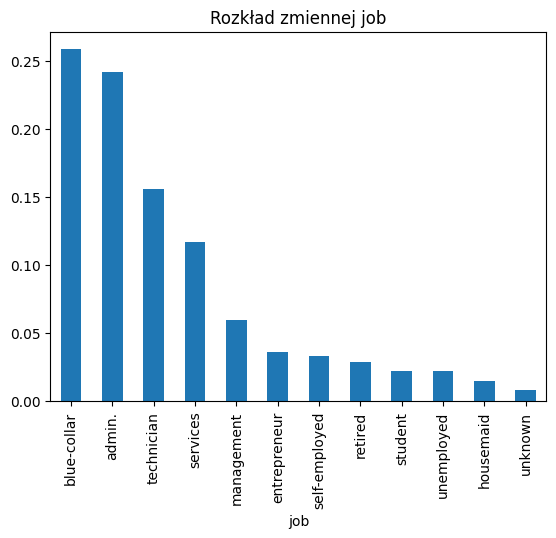

In [4]:
df['job'].value_counts(normalize=True).plot(kind='bar', title='Rozkład zmiennej job')

## 4. Wizualizacja wybranej cechy

Wybierz jedną cechę w następnej komórce. Dla wartości liczbowych zobaczysz rozkład w klasach `no` i `yes`; dla kategorii porównanie ich udziałów w obu klasach.
Zwróć szczególną uwagę na cechę 'duration'

duration – podsumowanie:


,yes,no
count,220.000000,1768.000000
mean,584.109091,220.500000
std,413.178245,196.285209
min,87.000000,-30.000000
25%,312.000000,96.000000
50%,502.500000,164.000000
75%,728.250000,275.000000
max,3094.000000,2053.000000


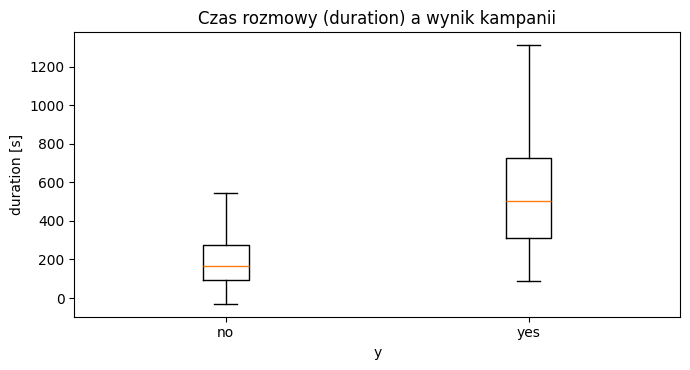

In [ ]:
from scripts.group_b import plot_feature_by_target

# Zmień cechę, np. "contact", "housing", "age" albo "duration".
CECHA = "contact"
plot_feature_by_target(df, CECHA)

## 5. Jaki odsetek klientów z danej kategorii założył lokatę?

Tutaj procent liczymy **wewnątrz kategorii**: liczba klientów `yes` podzielona przez wszystkich klientów `yes` i `no` w tej kategorii. Na przykład wiersz `job = admin` odpowiada na pytanie: „jaki odsetek adminów założył lokatę?”.

Tabela pokazuje też liczebność grupy i ogólny odsetek lokat w próbce jako punkt odniesienia. Małe grupy traktujcie ostrożnie.

In [4]:
from scripts.group_b import categorical_outcome_rates

tabela_kategorii = categorical_outcome_rates(df)
tabela_kategorii

,zmienna,kategoria,liczba klientów,y = no,y = yes,odsetek lokat w kategorii (%),odsetek lokat w całej próbce (%),różnica względem próbki (p.p.)
0,contact,cellular,1304,1116,188,14.4,11.0,3.4
1,contact,telephone,696,663,33,4.7,11.0,-6.3
2,education,illiterate,2,1,1,50.0,11.0,39.0
3,education,brak danych,24,20,4,16.7,11.0,5.6
4,education,university.degree,531,451,80,15.1,11.0,4.0
5,education,unknown,84,74,10,11.9,11.0,0.9
6,education,basic.6y,125,112,13,10.4,11.0,-0.7
7,education,basic.4y,201,182,19,9.5,11.0,-1.6
8,education,professional.course,244,221,23,9.4,11.0,-1.6
9,education,basic.9y,300,272,28,9.3,11.0,-1.7


## 6. Kiedy poszczególne informacje są dostępne?

In [7]:
from scripts.group_b import feature_context

feature_context()

,cecha,znaczenie,dostępność
0,age,wiek klienta,znane przed rozmową
1,job,rodzaj zatrudnienia,znane przed rozmową
2,education,poziom wykształcenia,znane przed rozmową
3,housing,kredyt mieszkaniowy: yes/no/unknown,znane przed rozmową
4,contact,rodzaj kanału kontaktu,znane przed / przy rozpoczęciu kontaktu
5,month,miesiąc ostatniego kontaktu,znane w momencie kontaktu
6,duration,czas trwania ostatniej rozmowy telefonicznej,znane dopiero po rozmowie
7,campaign,liczba kontaktów w bieżącej kampanii,zależy od momentu predykcji
8,pdays,dni od poprzedniego kontaktu; 999 oznacza brak...,historyczne


,cecha,znaczenie,dostępność
0,age,wiek klienta,znane przed rozmową
1,job,rodzaj zatrudnienia,znane przed rozmową
2,education,poziom wykształcenia,znane przed rozmową
3,housing,kredyt mieszkaniowy: yes/no/unknown,znane przed rozmową
4,contact,rodzaj kanału kontaktu,znane przed / przy rozpoczęciu kontaktu
5,month,miesiąc ostatniego kontaktu,znane w momencie kontaktu
6,duration,czas trwania ostatniej rozmowy telefonicznej,znane dopiero po rozmowie
7,campaign,liczba kontaktów w bieżącej kampanii,zależy od momentu predykcji
8,pdays,dni od poprzedniego kontaktu; 999 oznacza brak...,historyczne


## Przygotujcie 2–3 wnioski

1. Czy accuracy wystarczy?
2. Jaki baseline jest rozsądny?
3. Dlaczego bardzo silna różnica lub korelacja z targetem nie zawsze jest zaletą?
4. Które cechy wykorzystać w modelu przewidującym wynik **przed rozmową**, a które wykluczyć? Uzasadnijcie wybór, zwracając uwagę na `duration` i moment pomiaru `campaign`.
5. Która cecha może powodować data leakage?